In [1]:
# Import libraries for data manipulation and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import zipfile
import io

# Import tools for text preprocessing
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# Open the ZIP file containing the research datasets
zip_path = "Project 1 Required Resources-20261113.zip"

with zipfile.ZipFile(zip_path, "r") as zip_file:
    with zip_file.open("research_abstracts.json") as json_file:
        df = pd.read_json(json_file)

# Display dataset dimensions and first five records
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1138, 3)


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [3]:
# Display dataset information
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate abstracts
print("\nDuplicate abstracts:")
print(df.duplicated(subset=["Abstract"]).sum())

# Display the distribution of research categories
print("\nResearch categories:")
print(df["Label"].value_counts())


<class 'pandas.core.frame.DataFrame'>
Index: 1138 entries, 0 to 1137
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DOI       1134 non-null   object
 1   Abstract  1138 non-null   object
 2   Label     1138 non-null   object
dtypes: object(3)
memory usage: 35.6+ KB

Missing values:
DOI         4
Abstract    0
Label       0
dtype: int64

Duplicate abstracts:
13

Research categories:
Label
classical    900
ai           238
Name: count, dtype: int64


In [4]:
# Remove records with missing abstracts or labels
df = df.dropna(subset=["Abstract", "Label"]).copy()

# Remove abstracts containing only empty spaces
df = df[df["Abstract"].str.strip() != ""].copy()

# Remove repeated research abstracts
df = df.drop_duplicates(subset=["Abstract"])

# Reset dataframe index
df = df.reset_index(drop=True)

# Display cleaned dataset dimensions
print("Dataset shape after cleaning:", df.shape)
display(df.head())


Dataset shape after cleaning: (1125, 3)


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [5]:
# Define stopwords while retaining important negation terms
stop_words = set(ENGLISH_STOP_WORDS)

stop_words = stop_words.difference(
    {"no", "not", "nor", "without"}
)

# Define a function for cleaning research abstracts
def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Remove common English stopwords
    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    # Reconstruct the cleaned abstract
    cleaned_text = " ".join(filtered_words)

    return cleaned_text

# Apply the cleaning function
df["Cleaned_Abstract"] = df["Abstract"].apply(clean_text)

# Display original and cleaned abstracts
display(df[["Abstract", "Cleaned_Abstract"]].head())


,Abstract,Cleaned_Abstract
0,Forward-looking forecasting of the inflation r...,forward looking forecasting inflation rate hel...
1,Our study examined the disaggregation of infla...,study examined disaggregation inflation compon...
2,This paper develops a dynamic factor model tha...,paper develops dynamic factor model uses euro ...
3,"In this paper, I use a simple SIR Macro model ...",paper use simple sir macro model examine japan...
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory useful identifying condi...


In [6]:
# Compare the original and cleaned abstract
print("ORIGINAL ABSTRACT:\n")
print(df.loc[0, "Abstract"])

print("\nCLEANED ABSTRACT:\n")
print(df.loc[0, "Cleaned_Abstract"])

# Calculate the number of words before and after cleaning
df["Original_Word_Count"] = df["Abstract"].str.split().str.len()

df["Cleaned_Word_Count"] = df["Cleaned_Abstract"].str.split().str.len()

# Display descriptive statistics
display(
    df[["Original_Word_Count", "Cleaned_Word_Count"]].describe()
)


ORIGINAL ABSTRACT:

Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutions and investors better make investment decisions. In this sense, the forecast of inflation rate is of great significance. The existing literature mainly uses linear models such as autoregressive (AR) and vector autoregressive (VAR) models to predict the inflation rate. The nonlinear relationship between variables and the mining of historical data information are relatively lacking. Therefore, the prediction strategies and accuracy of the existing literature need to be improved. The predictive model designed in deep learning can fully mine the nonlinear relationship between variables and process complex long-term time series dynamic information, thereby making up for the 

,Original_Word_Count,Cleaned_Word_Count
count,1125.000000,1125.000000
mean,171.594667,101.584000
std,103.924594,61.713661
min,16.000000,9.000000
25%,116.000000,69.000000
50%,152.000000,91.000000
75%,201.000000,118.000000
max,2075.000000,1265.000000


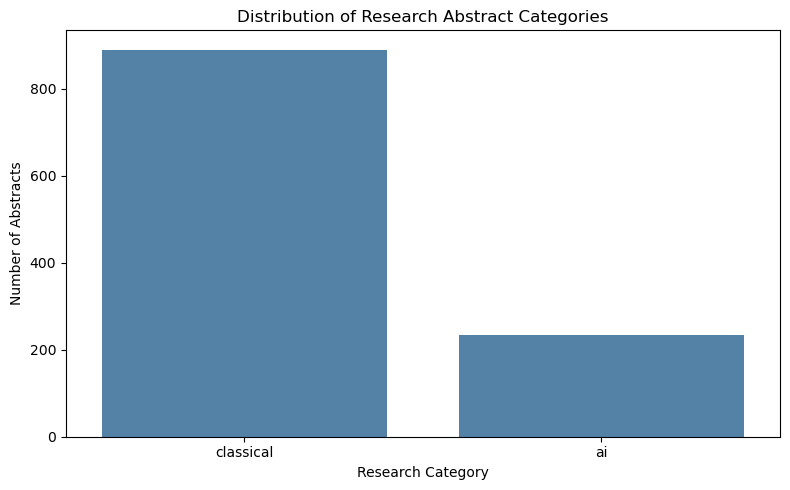

In [7]:
# Display the distribution of research categories
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Label",
    order=["classical", "ai"],
    color="steelblue"
)

plt.title("Distribution of Research Abstract Categories")
plt.xlabel("Research Category")
plt.ylabel("Number of Abstracts")

plt.tight_layout()
plt.show()


In [8]:
# Remove any records that became empty after text cleaning
df = df[df["Cleaned_Abstract"].str.strip() != ""].copy()

# Reset the index
df = df.reset_index(drop=True)

# Save the processed dataset
df.to_csv("cleaned_research_abstracts.csv", index=False)

print("Preprocessed dataset saved successfully.")
print("Final dataset shape:", df.shape)


Preprocessed dataset saved successfully.
Final dataset shape: (1125, 6)


# 1.2

In [9]:
# Import the train-test splitting function
from sklearn.model_selection import train_test_split

# Select cleaned research abstracts as input features
X = df["Cleaned_Abstract"]

# Select research categories as the target variable
y = df["Label"]

# Display the number of observations
print("Number of input abstracts:", X.shape[0])
print("Number of target labels:", y.shape[0])

# Display the target categories
print("\nTarget categories:")
print(y.value_counts())


Number of input abstracts: 1125
Number of target labels: 1125

Target categories:
Label
classical    890
ai           235
Name: count, dtype: int64


In [10]:
# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training and testing dimensions
print("Training abstracts:", X_train.shape[0])
print("Testing abstracts:", X_test.shape[0])

# Check the class distribution in each dataset
print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training abstracts: 900
Testing abstracts: 225

Training class distribution:
Label
classical    712
ai           188
Name: count, dtype: int64

Testing class distribution:
Label
classical    178
ai            47
Name: count, dtype: int64


In [11]:
# Import the TF-IDF vectorisation technique
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialise the TF-IDF vectoriser
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Learn the vocabulary and transform training abstracts
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform testing abstracts using the learned vocabulary
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Display the feature matrix dimensions
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

# Display the first 20 extracted features
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nFirst 20 features:")
print(feature_names[:20])


Training TF-IDF shape: (900, 5000)
Testing TF-IDF shape: (225, 5000)

First 20 features:
['ability' 'ability predict' 'able' 'able predict' 'absence' 'absolute'
 'absolute error' 'absolute percentage' 'abstract' 'abundant' 'academic'
 'accelerated' 'accelerator' 'accepted' 'access' 'accessible'
 'accommodate' 'accompanied' 'accordance' 'according']


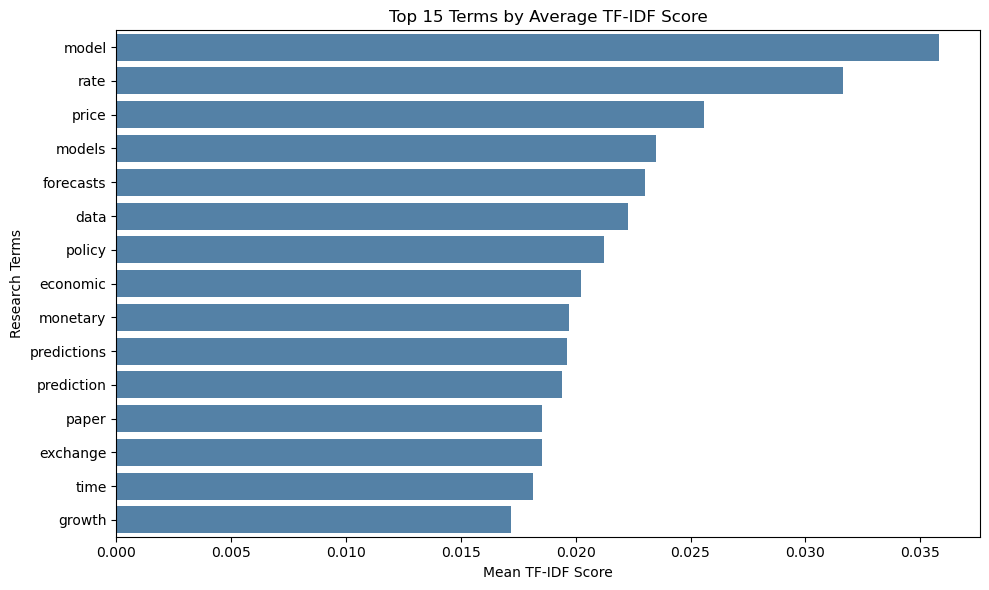

In [12]:
# Calculate the average TF-IDF score for each feature
mean_tfidf_scores = X_train_tfidf.mean(axis=0)

# Convert the scores into a one-dimensional array
mean_tfidf_scores = np.asarray(mean_tfidf_scores).flatten()

# Create a dataframe containing terms and their scores
tfidf_scores_df = pd.DataFrame({
    "Term": feature_names,
    "Mean_TFIDF": mean_tfidf_scores
})

# Select the 15 terms with the highest average scores
top_terms = tfidf_scores_df.nlargest(15, "Mean_TFIDF")

# Visualise the top TF-IDF terms
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_terms,
    x="Mean_TFIDF",
    y="Term",
    color="steelblue"
)

plt.title("Top 15 Terms by Average TF-IDF Score")
plt.xlabel("Mean TF-IDF Score")
plt.ylabel("Research Terms")

plt.tight_layout()
plt.show()


Feature engineering was performed using the TF-IDF vectorisation technique to transform the cleaned research abstracts into numerical representations suitable for machine learning. The cleaned abstract column was selected as the independent variable, while the research category label was selected as the dependent variable.

The dataset was divided into 80% training data and 20% testing data using stratified sampling to preserve class proportions. TF-IDF was fitted exclusively on the training dataset to prevent data leakage. The vectoriser considered both individual words and two-word phrases, with a maximum vocabulary size of 5,000 features.

The extracted numerical features provide a foundation for training and evaluating research abstract classification models.

# 1.3

In [13]:
# Import the Multinomial Naive Bayes classifier
from sklearn.naive_bayes import MultinomialNB

# Initialise the baseline classification model
baseline_model = MultinomialNB(alpha=1.0)

# Train the model using TF-IDF training features
baseline_model.fit(X_train_tfidf, y_train)

# Generate predictions for training data
y_train_pred = baseline_model.predict(X_train_tfidf)

# Generate predictions for unseen testing data
y_test_pred = baseline_model.predict(X_test_tfidf)

print("Baseline model trained successfully.")


Baseline model trained successfully.


In [14]:
# Import classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Calculate training accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)

# Calculate testing accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)

# Calculate precision for AI research classification
test_precision = precision_score(
    y_test,
    y_test_pred,
    pos_label="ai",
    zero_division=0
)

# Calculate recall for AI research classification
test_recall = recall_score(
    y_test,
    y_test_pred,
    pos_label="ai",
    zero_division=0
)

# Calculate F1-score for AI research classification
test_f1 = f1_score(
    y_test,
    y_test_pred,
    pos_label="ai",
    zero_division=0
)

# Display model evaluation results
print("BASELINE MODEL PERFORMANCE")
print("--------------------------")
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")
print(f"AI Precision:      {test_precision:.4f}")
print(f"AI Recall:         {test_recall:.4f}")
print(f"AI F1-score:       {test_f1:.4f}")


BASELINE MODEL PERFORMANCE
--------------------------
Training Accuracy: 0.9000
Testing Accuracy:  0.8489
AI Precision:      1.0000
AI Recall:         0.2766
AI F1-score:       0.4333


In [15]:

# Generate a detailed classification report
report = classification_report(
    y_test,
    y_test_pred,
    target_names=None,
    digits=4,
    zero_division=0
)

# Display the classification report
print("BASELINE CLASSIFICATION REPORT")
print(report)


BASELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

          ai     1.0000    0.2766    0.4333        47
   classical     0.8396    1.0000    0.9128       178

    accuracy                         0.8489       225
   macro avg     0.9198    0.6383    0.6731       225
weighted avg     0.8731    0.8489    0.8127       225



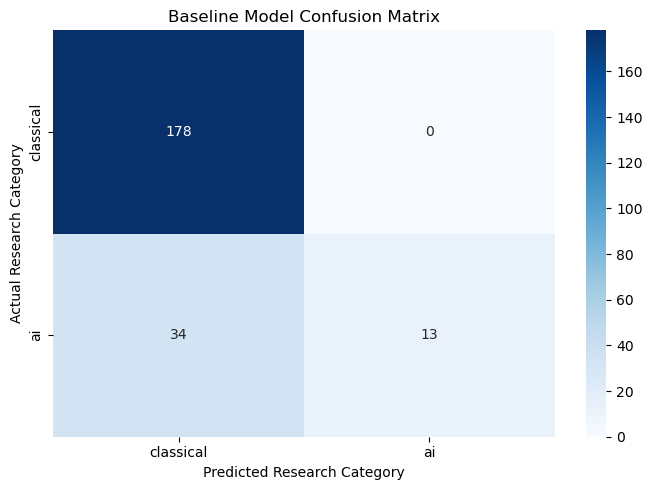

In [16]:
# Define the class order for evaluation
class_labels = ["classical", "ai"]

# Generate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

# Visualise the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Baseline Model Confusion Matrix")
plt.xlabel("Predicted Research Category")
plt.ylabel("Actual Research Category")

plt.tight_layout()
plt.show()


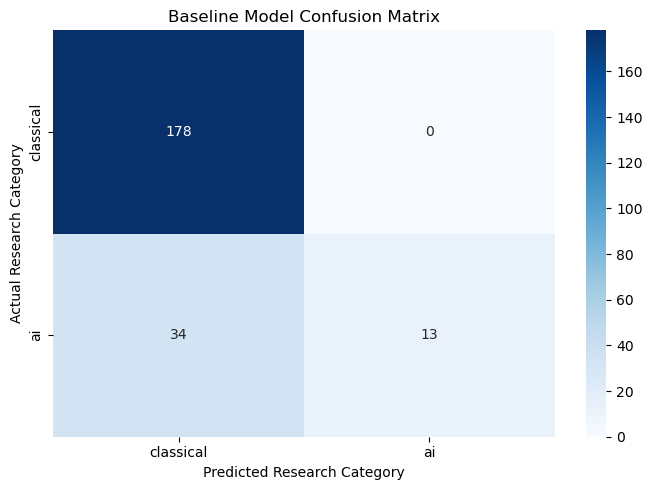

In [17]:
# Define the class order for evaluation
class_labels = ["classical", "ai"]

# Generate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

# Visualise the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Baseline Model Confusion Matrix")
plt.xlabel("Predicted Research Category")
plt.ylabel("Actual Research Category")

plt.tight_layout()
plt.show()


MODEL GENERALISATION
--------------------
Training Accuracy: 0.9000
Testing Accuracy:  0.8489
Accuracy Gap:      0.0511


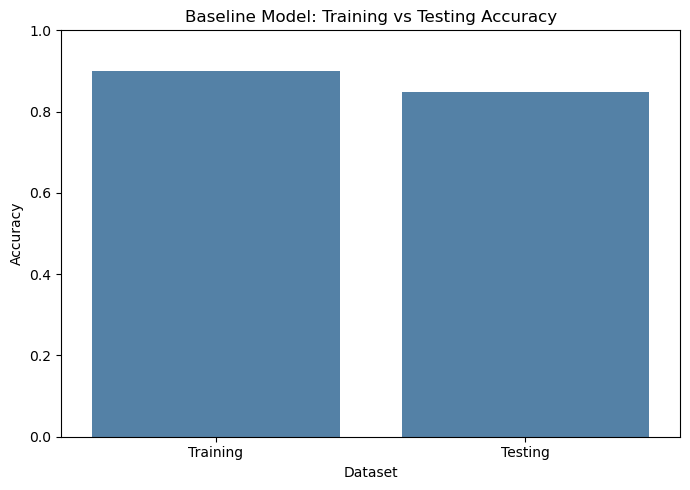

In [18]:
# Compare training and testing accuracy
generalisation_gap = train_accuracy - test_accuracy

print("MODEL GENERALISATION")
print("--------------------")
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")
print(f"Accuracy Gap:      {generalisation_gap:.4f}")

# Create a dataframe for visual comparison
performance_df = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [train_accuracy, test_accuracy]
})

# Visualise training and testing performance
plt.figure(figsize=(7, 5))

sns.barplot(
    data=performance_df,
    x="Dataset",
    y="Accuracy",
    color="steelblue"
)

plt.title("Baseline Model: Training vs Testing Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Dataset")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


In [19]:
# Import a simple majority-class classifier
from sklearn.dummy import DummyClassifier

# Initialise a classifier that predicts the majority class
dummy_model = DummyClassifier(strategy="most_frequent")

# Train the majority-class classifier
dummy_model.fit(X_train_tfidf, y_train)

# Generate predictions on testing data
dummy_predictions = dummy_model.predict(X_test_tfidf)

# Calculate majority-class accuracy
dummy_accuracy = accuracy_score(y_test, dummy_predictions)

# Calculate majority-class AI F1-score
dummy_f1 = f1_score(
    y_test,
    dummy_predictions,
    pos_label="ai",
    zero_division=0
)

# Compare baseline and majority-class performance
comparison_df = pd.DataFrame({
    "Model": ["Majority Class", "Multinomial Naive Bayes"],
    "Accuracy": [dummy_accuracy, test_accuracy],
    "AI_F1_Score": [dummy_f1, test_f1]
})

display(comparison_df)


,Model,Accuracy,AI_F1_Score
0,Majority Class,0.791111,0.000000
1,Multinomial Naive Bayes,0.848889,0.433333


Multinomial Naive Bayes classifier was implemented as the baseline model for classifying research abstracts into AI-related and classical research categories. The model was trained using TF-IDF features extracted from the training dataset and evaluated on previously unseen testing data.

Model performance was assessed using accuracy, precision, recall, F1-score and a confusion matrix. Training and testing accuracy were compared to assess the model's ability to generalise to unseen research abstracts.

Given the imbalance between the two research categories, particular attention was given to the precision, recall and F1-score of the AI class. The model was also compared against a majority-class classifier to determine whether it provided meaningful predictive performance beyond simply predicting the most frequent category.

The results of this baseline evaluation will serve as a benchmark for the additional machine learning algorithms developed in Question 1.2

# Question 2

In [20]:
# Import the machine learning classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

# Import model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Machine learning algorithms imported successfully.")


Machine learning algorithms imported successfully.


In [21]:
# Initialise Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Initialise Linear Support Vector Machine
svm_model = LinearSVC(
    random_state=42,
    max_iter=5000
)

# Initialise Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Initialise Gradient Boosting
gradient_boosting_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    random_state=42
)

print("Four classification models initialised.")


Four classification models initialised.


In [22]:
# Train Logistic Regression using TF-IDF features
logistic_model.fit(X_train_tfidf, y_train)

# Predict training and testing categories
logistic_train_pred = logistic_model.predict(X_train_tfidf)
logistic_test_pred = logistic_model.predict(X_test_tfidf)

# Calculate classification performance
logistic_accuracy = accuracy_score(y_test, logistic_test_pred)

logistic_precision = precision_score(
    y_test, logistic_test_pred, pos_label="ai", zero_division=0
)

logistic_recall = recall_score(
    y_test, logistic_test_pred, pos_label="ai", zero_division=0
)

logistic_f1 = f1_score(
    y_test, logistic_test_pred, pos_label="ai", zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-score:  {logistic_f1:.4f}")


LOGISTIC REGRESSION RESULTS
Accuracy:  0.8311
Precision: 1.0000
Recall:    0.1915
F1-score:  0.3214


In [23]:
# Train the Linear Support Vector Machine
svm_model.fit(X_train_tfidf, y_train)

# Predict training and testing categories
svm_train_pred = svm_model.predict(X_train_tfidf)
svm_test_pred = svm_model.predict(X_test_tfidf)

# Calculate classification performance
svm_accuracy = accuracy_score(y_test, svm_test_pred)

svm_precision = precision_score(
    y_test, svm_test_pred, pos_label="ai", zero_division=0
)

svm_recall = recall_score(
    y_test, svm_test_pred, pos_label="ai", zero_division=0
)

svm_f1 = f1_score(
    y_test, svm_test_pred, pos_label="ai", zero_division=0
)

print("LINEAR SVM RESULTS")
print(f"Accuracy:  {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall:    {svm_recall:.4f}")
print(f"F1-score:  {svm_f1:.4f}")


LINEAR SVM RESULTS
Accuracy:  0.9111
Precision: 0.9091
Recall:    0.6383
F1-score:  0.7500


In [24]:
# Train the Random Forest classifier
random_forest_model.fit(X_train_tfidf, y_train)

# Predict training and testing categories
rf_train_pred = random_forest_model.predict(X_train_tfidf)
rf_test_pred = random_forest_model.predict(X_test_tfidf)

# Calculate classification performance
rf_accuracy = accuracy_score(y_test, rf_test_pred)

rf_precision = precision_score(
    y_test, rf_test_pred, pos_label="ai", zero_division=0
)

rf_recall = recall_score(
    y_test, rf_test_pred, pos_label="ai", zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_test_pred, pos_label="ai", zero_division=0
)

print("RANDOM FOREST RESULTS")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")


RANDOM FOREST RESULTS
Accuracy:  0.9244
Precision: 1.0000
Recall:    0.6383
F1-score:  0.7792


In [25]:
# Convert sparse TF-IDF matrices to dense arrays
X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()

# Train the Gradient Boosting classifier
gradient_boosting_model.fit(X_train_dense, y_train)

# Predict training and testing categories
gb_train_pred = gradient_boosting_model.predict(X_train_dense)
gb_test_pred = gradient_boosting_model.predict(X_test_dense)

# Calculate classification performance
gb_accuracy = accuracy_score(y_test, gb_test_pred)

gb_precision = precision_score(
    y_test, gb_test_pred, pos_label="ai", zero_division=0
)

gb_recall = recall_score(
    y_test, gb_test_pred, pos_label="ai", zero_division=0
)

gb_f1 = f1_score(
    y_test, gb_test_pred, pos_label="ai", zero_division=0
)

print("GRADIENT BOOSTING RESULTS")
print(f"Accuracy:  {gb_accuracy:.4f}")
print(f"Precision: {gb_precision:.4f}")
print(f"Recall:    {gb_recall:.4f}")
print(f"F1-score:  {gb_f1:.4f}")


GRADIENT BOOSTING RESULTS
Accuracy:  0.9156
Precision: 0.9375
Recall:    0.6383
F1-score:  0.7595


In [26]:
# Create a dataframe comparing model performance
model_comparison = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "Linear SVM",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        test_accuracy,
        logistic_accuracy,
        svm_accuracy,
        rf_accuracy,
        gb_accuracy
    ],
    "AI Precision": [
        test_precision,
        logistic_precision,
        svm_precision,
        rf_precision,
        gb_precision
    ],
    "AI Recall": [
        test_recall,
        logistic_recall,
        svm_recall,
        rf_recall,
        gb_recall
    ],
    "AI F1-score": [
        test_f1,
        logistic_f1,
        svm_f1,
        rf_f1,
        gb_f1
    ]
})

# Sort models by AI F1-score
model_comparison = model_comparison.sort_values(
    by="AI F1-score",
    ascending=False
)

# Display comparison results
display(model_comparison.round(4))


,Model,Accuracy,AI Precision,AI Recall,AI F1-score
3,Random Forest,0.9244,1.0000,0.6383,0.7792
4,Gradient Boosting,0.9156,0.9375,0.6383,0.7595
2,Linear SVM,0.9111,0.9091,0.6383,0.7500
0,Multinomial Naive Bayes,0.8489,1.0000,0.2766,0.4333
1,Logistic Regression,0.8311,1.0000,0.1915,0.3214


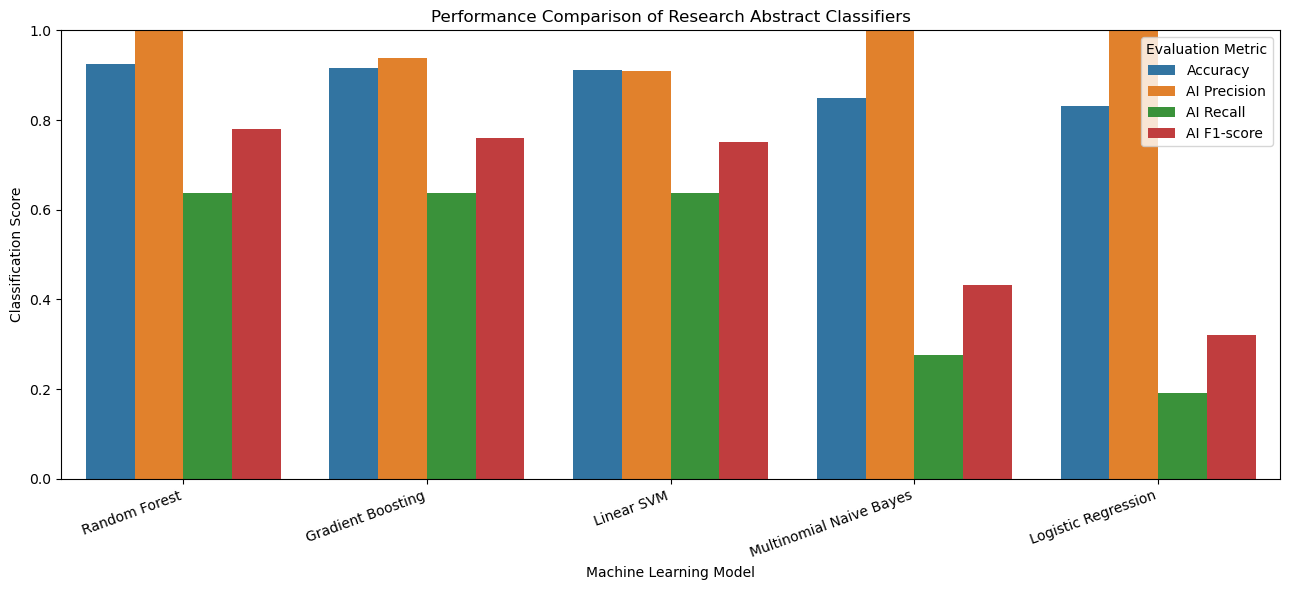

In [27]:
# Prepare model performance metrics for visualisation
comparison_long = model_comparison.melt(
    id_vars="Model",
    value_vars=["Accuracy", "AI Precision", "AI Recall", "AI F1-score"],
    var_name="Metric",
    value_name="Score"
)

# Create a grouped bar chart
plt.figure(figsize=(13, 6))

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Research Abstract Classifiers")
plt.xlabel("Machine Learning Model")
plt.ylabel("Classification Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metric")

plt.tight_layout()
plt.show()


In [28]:
# Identify the highest-performing model using AI F1-score
best_model_row = model_comparison.iloc[0]

best_model_name = best_model_row["Model"]
best_model_f1 = best_model_row["AI F1-score"]

# Display the best model
print("BEST PERFORMING MODEL")
print("---------------------")
print("Model:", best_model_name)
print(f"AI F1-score: {best_model_f1:.4f}")

# Compare its F1-score with the baseline
f1_improvement = best_model_f1 - test_f1

print(f"Improvement over baseline: {f1_improvement:.4f}")


BEST PERFORMING MODEL
---------------------
Model: Random Forest
AI F1-score: 0.7792
Improvement over baseline: 0.3459


Four machine learning algorithms were trained and evaluated to improve research abstract classification: Logistic Regression, Linear Support Vector Machine, Random Forest and Gradient Boosting.

Random Forest achieved the strongest predictive performance, with an accuracy of 92.44%, AI precision of 100%, AI recall of 63.83% and an AI F1-score of 77.92%. This represents an improvement of 34.59 percentage points in AI F1-score compared with the Multinomial Naive Bayes baseline of 43.33%.

Gradient Boosting and Linear SVM also performed well, achieving AI F1-scores of 75.95% and 75.00%, respectively. However, Logistic Regression performed below the baseline in AI F1-score.

Random Forest was therefore selected as the best-performing model for further optimisation in Question 2.2. Although it achieved high precision, its recall indicates that some AI-related abstracts remain incorrectly classified, providing an opportunity for further performance improvement.

# 2.2

In [29]:
# Import hyperparameter tuning tools
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# Define AI F1-score as the optimisation metric
ai_f1_scorer = make_scorer(
    f1_score,
    pos_label="ai",
    zero_division=0
)

print("GridSearchCV tools imported successfully.")


GridSearchCV tools imported successfully.


In [30]:
# Define hyperparameter combinations for Random Forest
parameter_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"]
}

# Initialise Random Forest for tuning
rf_tuning_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Configure grid search with stratified cross-validation
grid_search = GridSearchCV(
    estimator=rf_tuning_model,
    param_grid=parameter_grid,
    scoring=ai_f1_scorer,
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Hyperparameter search configured.")


Hyperparameter search configured.


In [31]:
# Search for the best hyperparameter combination
grid_search.fit(X_train_tfidf, y_train)

# Retrieve the best model configuration
tuned_rf_model = grid_search.best_estimator_

# Display the best hyperparameters
print("BEST HYPERPARAMETERS")
print(grid_search.best_params_)

# Display the best cross-validation F1-score
print("\nBest cross-validation AI F1-score:")
print(round(grid_search.best_score_, 4))


Fitting 5 folds for each of 16 candidates, totalling 80 fits
BEST HYPERPARAMETERS
{'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 100}

Best cross-validation AI F1-score:
0.7376


In [32]:
# Generate predictions using the tuned model
tuned_rf_train_pred = tuned_rf_model.predict(X_train_tfidf)
tuned_rf_test_pred = tuned_rf_model.predict(X_test_tfidf)

# Calculate testing performance
tuned_accuracy = accuracy_score(y_test, tuned_rf_test_pred)

tuned_precision = precision_score(
    y_test,
    tuned_rf_test_pred,
    pos_label="ai",
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    tuned_rf_test_pred,
    pos_label="ai",
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_rf_test_pred,
    pos_label="ai",
    zero_division=0
)

# Display tuned model performance
print("TUNED RANDOM FOREST PERFORMANCE")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-score:  {tuned_f1:.4f}")

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_rf_test_pred,
    digits=4,
    zero_division=0
))


TUNED RANDOM FOREST PERFORMANCE
Accuracy:  0.9111
Precision: 0.9091
Recall:    0.6383
F1-score:  0.7500

Classification Report:
              precision    recall  f1-score   support

          ai     0.9091    0.6383    0.7500        47
   classical     0.9115    0.9831    0.9459       178

    accuracy                         0.9111       225
   macro avg     0.9103    0.8107    0.8480       225
weighted avg     0.9110    0.9111    0.9050       225



In [33]:
# Compare original and tuned Random Forest performance
tuning_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        rf_accuracy,
        tuned_accuracy
    ],
    "AI Precision": [
        rf_precision,
        tuned_precision
    ],
    "AI Recall": [
        rf_recall,
        tuned_recall
    ],
    "AI F1-score": [
        rf_f1,
        tuned_f1
    ]
})

# Display performance comparison
display(tuning_comparison.round(4))

# Calculate improvement in AI F1-score
tuning_improvement = tuned_f1 - rf_f1

print(f"Change in AI F1-score: {tuning_improvement:.4f}")


,Model,Accuracy,AI Precision,AI Recall,AI F1-score
0,Original Random Forest,0.9244,1.0000,0.6383,0.7792
1,Tuned Random Forest,0.9111,0.9091,0.6383,0.7500


Change in AI F1-score: -0.0292


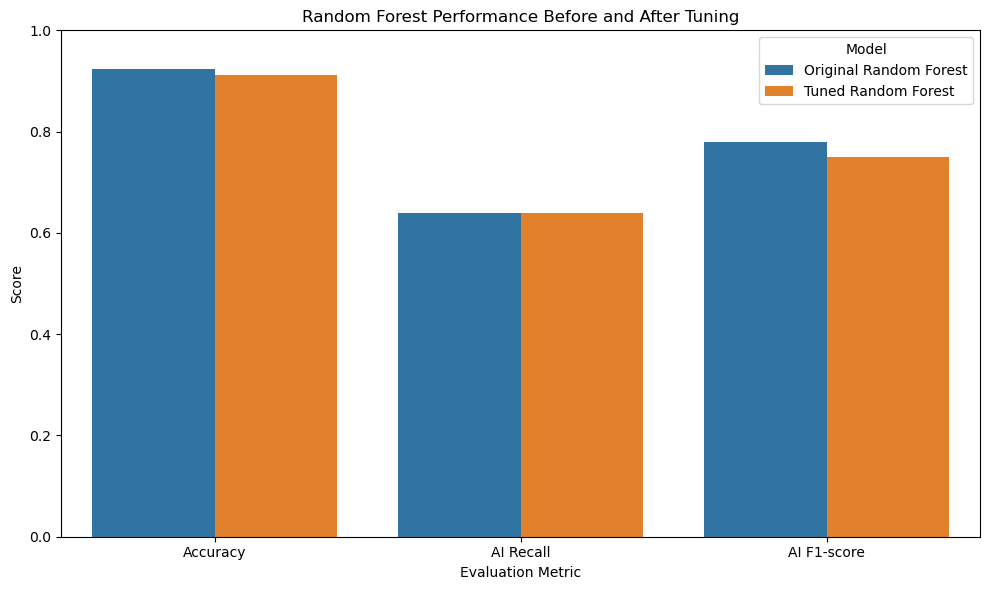

In [34]:
# Prepare performance results for visualisation
tuning_long = tuning_comparison.melt(
    id_vars="Model",
    value_vars=["Accuracy", "AI Recall", "AI F1-score"],
    var_name="Metric",
    value_name="Score"
)

# Plot original versus tuned Random Forest
plt.figure(figsize=(10, 6))

sns.barplot(
    data=tuning_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Random Forest Performance Before and After Tuning")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


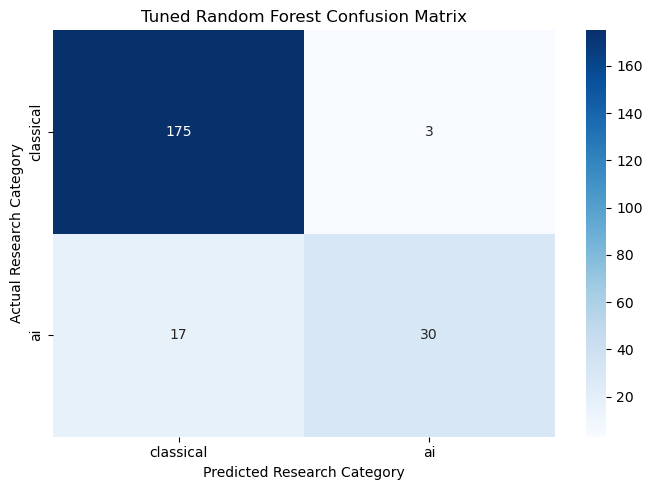

In [35]:
# Generate the confusion matrix for the tuned model
tuned_cm = confusion_matrix(
    y_test,
    tuned_rf_test_pred,
    labels=["classical", "ai"]
)

# Visualise the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    tuned_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["classical", "ai"],
    yticklabels=["classical", "ai"]
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.xlabel("Predicted Research Category")
plt.ylabel("Actual Research Category")

plt.tight_layout()
plt.show()


In [36]:
# Import cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Configure stratified five-fold cross-validation
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probabilities using the original Random Forest
cv_probabilities = cross_val_predict(
    random_forest_model,
    X_train_tfidf,
    y_train,
    cv=cross_validation,
    method="predict_proba",
    n_jobs=-1
)

# Identify the probability column for AI research
ai_class_index = list(random_forest_model.classes_).index("ai")

# Extract AI probabilities
cv_ai_probabilities = cv_probabilities[:, ai_class_index]

print("Cross-validation probabilities generated.")


Cross-validation probabilities generated.


In [37]:
# Define candidate probability thresholds
thresholds = np.arange(0.10, 0.91, 0.05)

# Store threshold evaluation results
threshold_results = []

# Evaluate AI classification performance at each threshold
for threshold in thresholds:

    predicted_labels = np.where(
        cv_ai_probabilities >= threshold,
        "ai",
        "classical"
    )

    precision = precision_score(
        y_train, predicted_labels,
        pos_label="ai", zero_division=0
    )

    recall = recall_score(
        y_train, predicted_labels,
        pos_label="ai", zero_division=0
    )

    f1 = f1_score(
        y_train, predicted_labels,
        pos_label="ai", zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "AI Precision": precision,
        "AI Recall": recall,
        "AI F1-score": f1
    })

# Convert results into a dataframe
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,AI Precision,AI Recall,AI F1-score
0,0.10,0.3212,0.9362,0.4783
1,0.15,0.4580,0.8989,0.6068
2,0.20,0.5891,0.8617,0.6998
3,0.25,0.6864,0.8032,0.7402
4,0.30,0.7929,0.7128,0.7507
5,0.35,0.8936,0.6702,0.7660
6,0.40,0.9444,0.6330,0.7580
7,0.45,0.9739,0.5957,0.7393
8,0.50,0.9815,0.5638,0.7162
9,0.55,0.9896,0.5053,0.6690


Optimal threshold: 0.35
Cross-validation AI F1-score: 0.766


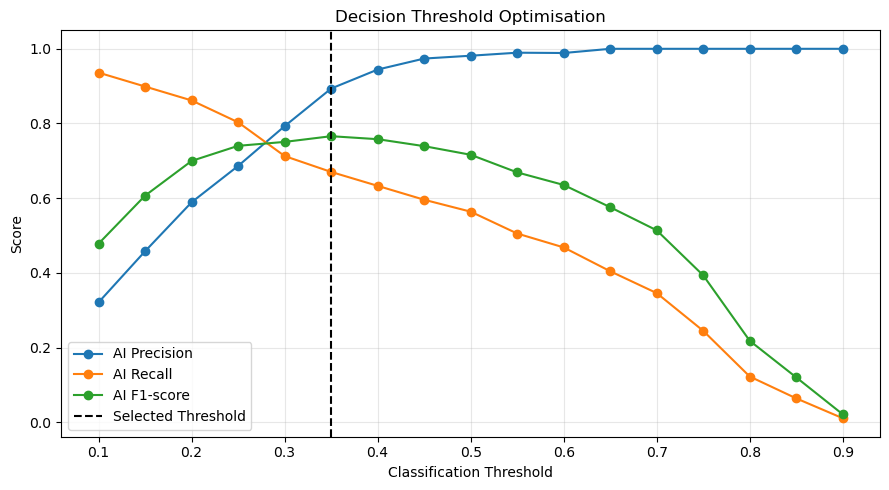

In [38]:
# Select the threshold with the highest cross-validation AI F1-score
best_threshold_row = threshold_df.loc[
    threshold_df["AI F1-score"].idxmax()
]

best_threshold = float(best_threshold_row["Threshold"])

print("Optimal threshold:", best_threshold)
print(
    "Cross-validation AI F1-score:",
    round(best_threshold_row["AI F1-score"], 4)
)

# Visualise the effect of threshold adjustment
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["AI Precision"],
    marker="o",
    label="AI Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["AI Recall"],
    marker="o",
    label="AI Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["AI F1-score"],
    marker="o",
    label="AI F1-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    color="black",
    label="Selected Threshold"
)

plt.title("Decision Threshold Optimisation")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [39]:
# Generate test probabilities using the original Random Forest
test_probabilities = random_forest_model.predict_proba(
    X_test_tfidf
)

# Extract probabilities for AI research
test_ai_probabilities = test_probabilities[:, ai_class_index]

# Apply the selected classification threshold
threshold_test_pred = np.where(
    test_ai_probabilities >= best_threshold,
    "ai",
    "classical"
)

# Calculate classification performance
threshold_accuracy = accuracy_score(
    y_test, threshold_test_pred
)

threshold_precision = precision_score(
    y_test, threshold_test_pred,
    pos_label="ai", zero_division=0
)

threshold_recall = recall_score(
    y_test, threshold_test_pred,
    pos_label="ai", zero_division=0
)

threshold_f1 = f1_score(
    y_test, threshold_test_pred,
    pos_label="ai", zero_division=0
)

# Display results
print("THRESHOLD-OPTIMISED RANDOM FOREST")
print(f"Accuracy:  {threshold_accuracy:.4f}")
print(f"Precision: {threshold_precision:.4f}")
print(f"Recall:    {threshold_recall:.4f}")
print(f"F1-score:  {threshold_f1:.4f}")


THRESHOLD-OPTIMISED RANDOM FOREST
Accuracy:  0.9244
Precision: 0.8750
Recall:    0.7447
F1-score:  0.8046


In [40]:
# Compare original, tuned and threshold-optimised models
final_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Hyperparameter-Tuned Random Forest",
        "Threshold-Optimised Random Forest"
    ],
    "Accuracy": [
        rf_accuracy,
        tuned_accuracy,
        threshold_accuracy
    ],
    "AI Recall": [
        rf_recall,
        tuned_recall,
        threshold_recall
    ],
    "AI F1-score": [
        rf_f1,
        tuned_f1,
        threshold_f1
    ]
})

display(final_comparison.round(4))


,Model,Accuracy,AI Recall,AI F1-score
0,Original Random Forest,0.9244,0.6383,0.7792
1,Hyperparameter-Tuned Random Forest,0.9111,0.6383,0.7500
2,Threshold-Optimised Random Forest,0.9244,0.7447,0.8046


2.2---

Predictive performance enhancement was investigated using hyperparameter tuning and decision-threshold optimisation. Initially, GridSearchCV was applied to the Random Forest classifier using five-fold cross-validation. The optimised hyperparameters produced an AI F1-score of 75.00%, compared with 77.92% for the original model, indicating that hyperparameter tuning did not improve testing performance.

Decision-threshold optimisation was subsequently implemented to improve the classification of AI-related research abstracts. Using cross-validation predictions from the training dataset, a threshold of 0.35 was selected, achieving a cross-validation AI F1-score of 76.60%.

When evaluated on the testing dataset, the threshold-optimised Random Forest achieved 92.44% accuracy, 87.50% AI precision, 74.47% AI recall and an AI F1-score of 80.46%.

Compared with the original Random Forest, AI recall improved by 10.64 percentage points, while the AI F1-score increased by 2.54 percentage points. Overall accuracy remained unchanged at 92.44%.

The improved recall demonstrates that lowering the classification threshold enabled the model to identify more AI-related abstracts, although this introduced additional false-positive predictions.

so, the threshold-optimised Random Forest was selected as the preferred configuration for deployment, as it achieved the highest observed AI F1-score while maintaining overall classification accuracy.

In [41]:
#3.3
# Import the library for saving trained models
import joblib

# Save the original Random Forest model
joblib.dump(
    random_forest_model,
    "researchly_random_forest.pkl"
)

# Save the fitted TF-IDF vectoriser
joblib.dump(
    tfidf_vectorizer,
    "researchly_tfidf.pkl"
)

# Save the optimised classification threshold
joblib.dump(
    best_threshold,
    "researchly_threshold.pkl"
)

print("Model, vectoriser and threshold saved successfully.")


Model, vectoriser and threshold saved successfully.


In [42]:
# Install Streamlit for web application development
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.
